# 02 – Forecast skill (E1, E2) and error propagation to exposure (E7)

Inputs: `data/mrc_derived/forecast_test.json` (observed Tan Chau stage, MRC data, and the model forecasts for the test
period 2023–2024) and the flood model. Every table is recomputed and compared with the paper by
`python -m analysis.reproduce_all`.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
pd.options.display.float_format = "{:,.3f}".format

from analysis.forecast_skill import Forecasts
from analysis.flood_model import FloodModel
fc = Forecasts(ROOT / "data/mrc_derived/forecast_test.json")
fm = FloodModel(ROOT / "data/derived/grids_public.npz", ROOT / "data/mrc_derived/calib.json")
print(fc.n, "test days;", fc.dates[0], "to", fc.dates[-1], "; test-set peak", fc.H.max(), "m")

731 test days; 2023-01-01 to 2024-12-31 ; test-set peak 3.169 m


## E1 – M1 stage forecast, RMSE (m) by model and horizon (paper Table `e1rmse`)

In [2]:
fc.e1_rmse_table()

,1 d,2 d,3 d,5 d,7 d,14 d
DT,0.090,0.149,0.184,0.215,0.230,0.269
RF,0.082,0.115,0.139,0.178,0.192,0.216
LightGBM,0.083,0.113,0.134,0.158,0.179,0.210
CatBoost,0.079,0.107,0.132,0.153,0.176,0.211
SVR,0.077,0.104,0.126,0.148,0.157,0.187
Blend,0.075,0.102,0.123,0.147,0.157,0.187
Persistence,0.088,0.136,0.178,0.248,0.295,0.345
Climatology,0.238,0.239,0.239,0.239,0.239,0.240
n pairs,730.000,729.000,728.000,726.000,724.000,717.000


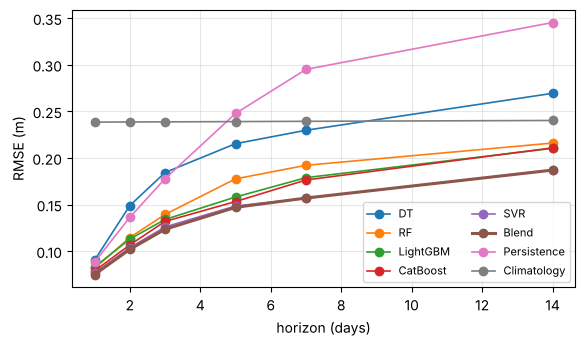

In [3]:
t = fc.e1_rmse_table()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for name in ["DT", "RF", "LightGBM", "CatBoost", "SVR", "Blend", "Persistence", "Climatology"]:
    ax.plot([1, 2, 3, 5, 7, 14], t.loc[name].iloc[:6].values, marker="o", lw=2.2 if name == "Blend" else 1.2, label=name)
ax.set_xlabel("horizon (days)"); ax.set_ylabel("RMSE (m)"); ax.legend(ncol=2, fontsize=8); ax.grid(alpha=.3)
plt.show()

## E1 – Blend against persistence and climatology (paper Table `e1blend`)

95 % intervals: 30-day block bootstrap, 2,000 resamples, seed 20261017; DM: Diebold–Mariano with the Harvey–Leybourne–Newbold correction.

In [4]:
fc.e1_blend_table()

,horizon,MAE,bias,NSE,persist_red_%,persist_ci_lo,persist_ci_hi,persist_p_DM,clim_red_%,clim_ci_lo,clim_ci_hi,clim_p_DM
0,1,0.056,0.005,0.991,15.170,11.765,19.571,0.000,68.579,60.276,75.400,0.000
1,2,0.080,0.010,0.984,25.195,20.231,30.501,0.000,57.264,46.910,65.784,0.000
2,3,0.097,0.010,0.976,30.563,25.307,36.077,0.000,48.276,36.958,57.876,0.000
3,5,0.117,0.012,0.966,40.673,35.363,45.286,0.000,38.505,26.998,48.158,0.000
4,7,0.126,0.015,0.962,46.795,41.288,51.590,0.000,34.406,22.392,44.377,0.001
5,14,0.140,0.014,0.946,45.853,36.246,52.744,0.000,22.159,13.365,30.240,0.005


## E1 – detection of stage ≥ 3.0 m (paper Table `alert`)

The test set has no day at Alarm level I (3.5 m); the highest stage is 3.169 m.

In [5]:
fc.e1_alert_table()

,hit,miss,false_alarm,correct_neg,POD,FAR,CSI
"Blend, value at day 7",6.000,10.000,3.000,705.000,0.375,0.333,0.316
"Persistence, value at day 7",9.000,7.000,7.000,701.000,0.562,0.438,0.391
"Blend, operational rule (peak in 7 days)",18.000,5.000,0.000,701.000,0.783,0.000,0.783
"Persistence, operational rule (peak in 7 days)",16.000,7.000,0.000,701.000,0.696,0.000,0.696


## E2 – seasonal targets M2, M3b, M4 (paper Table `e2`)

M2 is clipped to [0, 10] days (a count within a 10-day window); M4 CSI uses the probability thresholds chosen on the 2022 validation year.

In [6]:
fc.e2_table()

,M2 MAE,M3b MAE,M4-7d Brier,M4-7d AUC,M4-7d CSI,M4-15d Brier,M4-15d AUC,M4-15d CSI
DT,0.982,7.441,0.217,0.751,0.489,0.243,0.726,0.462
RF,0.936,5.207,0.178,0.828,0.518,0.177,0.838,0.593
LightGBM,0.891,4.507,0.152,0.866,0.557,0.178,0.845,0.598
CatBoost,0.853,4.786,0.169,0.858,0.546,0.170,0.846,0.609
SVR,1.861,4.416,0.166,0.826,0.589,0.166,0.832,0.613
Blend,1.013,4.462,0.151,0.867,0.545,0.166,0.832,0.613
Baseline,2.981,7.680,0.210,0.763,0.558,0.213,0.786,0.606


## E7 – propagation of forecast error to exposed population (paper Table `e7`)

The flood map is run with the observed stage and with the Blend forecast for the same target day. About 1–2 minutes.

In [7]:
e7 = fc.e7_table(fm)
e7

,horizon,n_all,dP_mean_all,n_high,dP_mean_high,dP_pct_high,missed_high,spurious_high,IoU_high
0,1,730,691.046,73,"3,381.358",5.464,"1,729.878","1,651.479",0.971
1,2,729,"1,187.681",73,"5,747.952",9.287,"2,610.816","3,137.136",0.953
2,3,728,"1,352.010",73,"6,910.093",11.165,"4,558.003","2,352.090",0.947
3,5,726,"2,145.986",73,"12,552.859",20.283,"8,519.066","4,033.793",0.899
4,7,724,"2,250.091",73,"12,270.432",19.826,"8,521.514","3,748.918",0.901
5,14,717,"2,923.555",73,"13,618.056",22.004,"11,046.135","2,571.921",0.891
